# Machine Learning Final Project: 
## Neuro-Symbolic Differentiable Rule Extractor (NSDRE)

**Creator**: Iman Sharifi, G46454668

In [9]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, entropy_threshold=1):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('?')
            continue

        # Find predicate value of a given neuron
        pred_value = pred_values[i]
        body_pred = body_preds[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'{body_pred}')
            continue
        elif max_index == 1:
            interpretations.append(f'not({body_pred})')
            continue
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('?')
            continue

        pred_value = pred_values[i]
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
        max_index = np.argmax(new_weights)

        if max_index == 0:
            interpretations.append(f'b{i+1}')
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights_(pred_values, Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # Find predicate value of a given neuron
        pred_value = pred_values[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights(Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # compute {weights[0], weights[1], weights[2]}
        new_weights = [weights[0], weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

## Learning desire rules from posivitive and negative examples and boolean inputs

## Learning diverse rules using NSDRE

Example rule: 

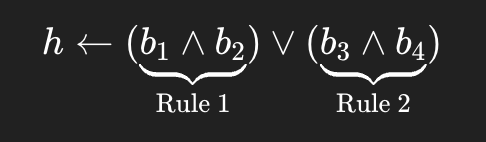

$h \leftarrow h_1 \vee h_2$

$h_1 \leftarrow b_1 \wedge b_2$

$h_2 \leftarrow b_3 \wedge b_4$

Considering a simple Fuzzy Disjunction Layer (like DFORL paper) -> didn't work

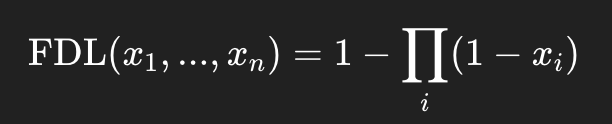

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        # self.weights = torch.sigmoid(self.raw_weights)
        # # Normalize weights to sum to 1
        # self.weights = self.weights / self.weights.sum()
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3

        # Fuzzy OR operation using the weights
        fuzzy_or = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3)

        return torch.log(fuzzy_or)

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])
        # self.raw_rule_weights = nn.Parameter(torch.randn(num_rules))  # Initialize rule weights
        self.raw_sigmoid_center_weight = nn.Parameter(torch.randn(num_rules) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []
        self.adjust_sigmoid_center = 0.5 * torch.sigmoid(self.raw_sigmoid_center_weight)  # Ensure sigmoid center is between 0 and 0.5

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            rule_output = torch.exp(sum(conjunctions))
            activated_rule_output = torch.sigmoid(5 * (rule_output - self.adjust_sigmoid_center[i]))
            rule_outputs.append(activated_rule_output)

        # Multiply the rule outputs with the rule weights
        # print("Rule Weights:", self.rule_weights)
        # rule_outputs = [output * weight for output, weight in zip(rule_outputs, self.rule_weights)]
        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        return fuzzy_or

In [11]:
def compute_acc_ratio(model, x, y, rule_idx):
    with torch.no_grad():
        rule = model.rules[rule_idx]
        body_conj = sum(rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule))
        rule_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            rule_weights.append(weights)

        num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.round(w[2]) == 1.0])
        threshold = 0.5**(num_body_preds)
        body = (torch.exp(body_conj) >= threshold).float()

        # Match the shape of body with y
        if body.shape != y.shape:
            body = body.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(body, y)

        return cos_sim.item()

def compute_acc_ratio_all_rules(model, x, y):
    with torch.no_grad():
        for rule_idx, rule in enumerate(model.rules):
            body_conj = sum(rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule))
            rule_weights = []
            for neuron in rule:
                weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
                rule_weights.append(weights)

            # This should be double checked because it may not be accurate
            num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.argmax(w) == 2 and np.round(w[2]) == 1.0]) # x.shape[1] is the number of potential body predicates
            threshold = 0.5**(num_body_preds)
            body = (torch.exp(body_conj) >= threshold).float()

            if rule_idx == 0:
                fuzzy_or = body
            else:
                fuzzy_or = fuzzy_or + body - fuzzy_or * body

        # Match the shape of body with y
        if fuzzy_or.shape != y.shape:
            fuzzy_or = fuzzy_or.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(fuzzy_or, y)

        return cos_sim.item()

# compute_acc_ratio(best_model, X_train, y_train, 0)

## The most stable version of the code:

1 - Added Multiple Initial values

2 - Added entropy for weight exploration 

## Learning More than one rule using NSDRE

## Example rule: 

### $h \leftarrow h_1 \vee h_2$

- $h_1 \leftarrow b_1 \wedge \neg b_2$

- $h_2 \leftarrow b_3 \wedge b_4$

Num Rules: 1, Restart 1/1, Final Loss: 0.5281.
Overall accuracy ratio: 0.6804
Num Rules: 2, Restart 1/1, Final Loss: 0.4072.
Overall accuracy ratio: 0.8293
Num Rules: 3, Restart 1/1, Final Loss: 0.3998.
Overall accuracy ratio: 0.8073
Num Rules: 4, Restart 1/1, Final Loss: 0.4488.
Overall accuracy ratio: 0.6892


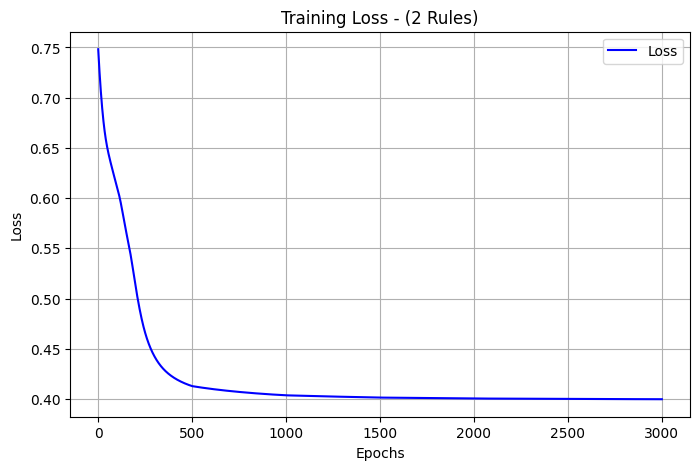

The most repeated rule is: 'h1 :- b3 and b4.'
Accuracy over training data: 1.0.
The most repeated rule is: 'h2 :- b1 and not(b2).'
Accuracy over training data: 1.0.

Final Rule:
h :- b3 and b4 OR b1 and not(b2).


In [13]:
from collections import Counter
# Parameters
Num_rules = 4
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000
num_epochs = 3000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# define y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float() using &
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_acc_ratio = 0
best_losses = []

for num_rules in range(Num_rules):

    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules + 1, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            # best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

        # Compute acc_ratio on training data
        # for r in range(len(model_nsre.rules)):
        #     acc_ratio = compute_acc_ratio(model_nsre, X_train, y_train, r)
        #     print(f"Rule {r + 1} accuracy ratio: {acc_ratio:.4f}")
        acc_ratio_all = compute_acc_ratio_all_rules(model_nsre, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
# Load the best model
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)
# print("\nFinal Weights of the Network:")
# for i, weights in enumerate(Weights_nsre):
#     print(f"Rule {i+1}: {weights}")

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_entropy(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


## Learning Structured Rules

Given this set of potential predicates $\{b_1(X_1, X_2), b_2(X_1), b_3(X_2, X_3), b_4(X_1, X_3)\}$ and the binary values for the head predicate $h(X_1, X_3)$, we aim to find the following target rule:

$h(X_1, X_3) :- b_1(X_1, X_2) \wedge \neg b_3(X_2, X_3)$,

where head variables are $X_1$ and $X_3$, and $X_2$ is an auxiliary variable. Each rule should satisfy these two conditions:

- Head variables should be present in the body of the rule.

- Auxiliary variables either should not be available in the body of the rule or should be available at least twice.

To enforce such conditions, we consider the following vector embeddings:

$X = [X_m]_{j=1}^m$, where $x_j$ is the probability of the existense of variable $X_j$ in the body predicates. The desired body variable embedding vector for the aforementioned target rule is $X_d = [X_1 = 1 , X_2 = 2, X_3 = 1, ..., X_m = 0]$

To find the variable embeddings for each rule, we firstly find the probablity of existense of a given predicate in the rule using its associated trainable weights. We know that each predicate $B_i$ has three weights $w_i^1$, $w_i^2$, and $w_i^3$ corresponding to $b_i$, $\neg b_i$, and $1$. Given this, we know that $w_i^3$ shows the probability of $B_i$ not being in the body of the rule. Therefore, $1-w_i^3$ is the probability of a given predicate appearing in the body of the rule at each training step, meaning $P = [1-w_i^3]_{i=1}^n$.

In the next step, we find the vector embeddings showing the existense of a given predicate in each potential predicate. Assume we have such potential predicates $\{B_i\}_{i=1}^n$ and variables $\{X_j\}_{j=1}^m$. If we assume that $v_{ij}$ is the probability of existense of variable $X_j$ in $B_i$, $v_{ij}$ is either 0 or 1, meaning $v_{ij} \in \{0, 1\}$. $V = [v_{ij}]_{n \times m}$ is a binary matrix describing the existense of a given variable in a given predicate.

Then the final probability vector is extracted using the following equation:
$M = P.V = [M_j]_{j=1}^m$


## Additional Loss Functions

1- Range Restricted Loss Function

$P_R = \prod_{i \in V_h} M[X_i]$

$L_R = MEAN(SIGMOID(-10(P_R-0.5))$

2- Connected Loss Function

$L_C = MEAN(0.5*N(MU=1, STD=0.2))$



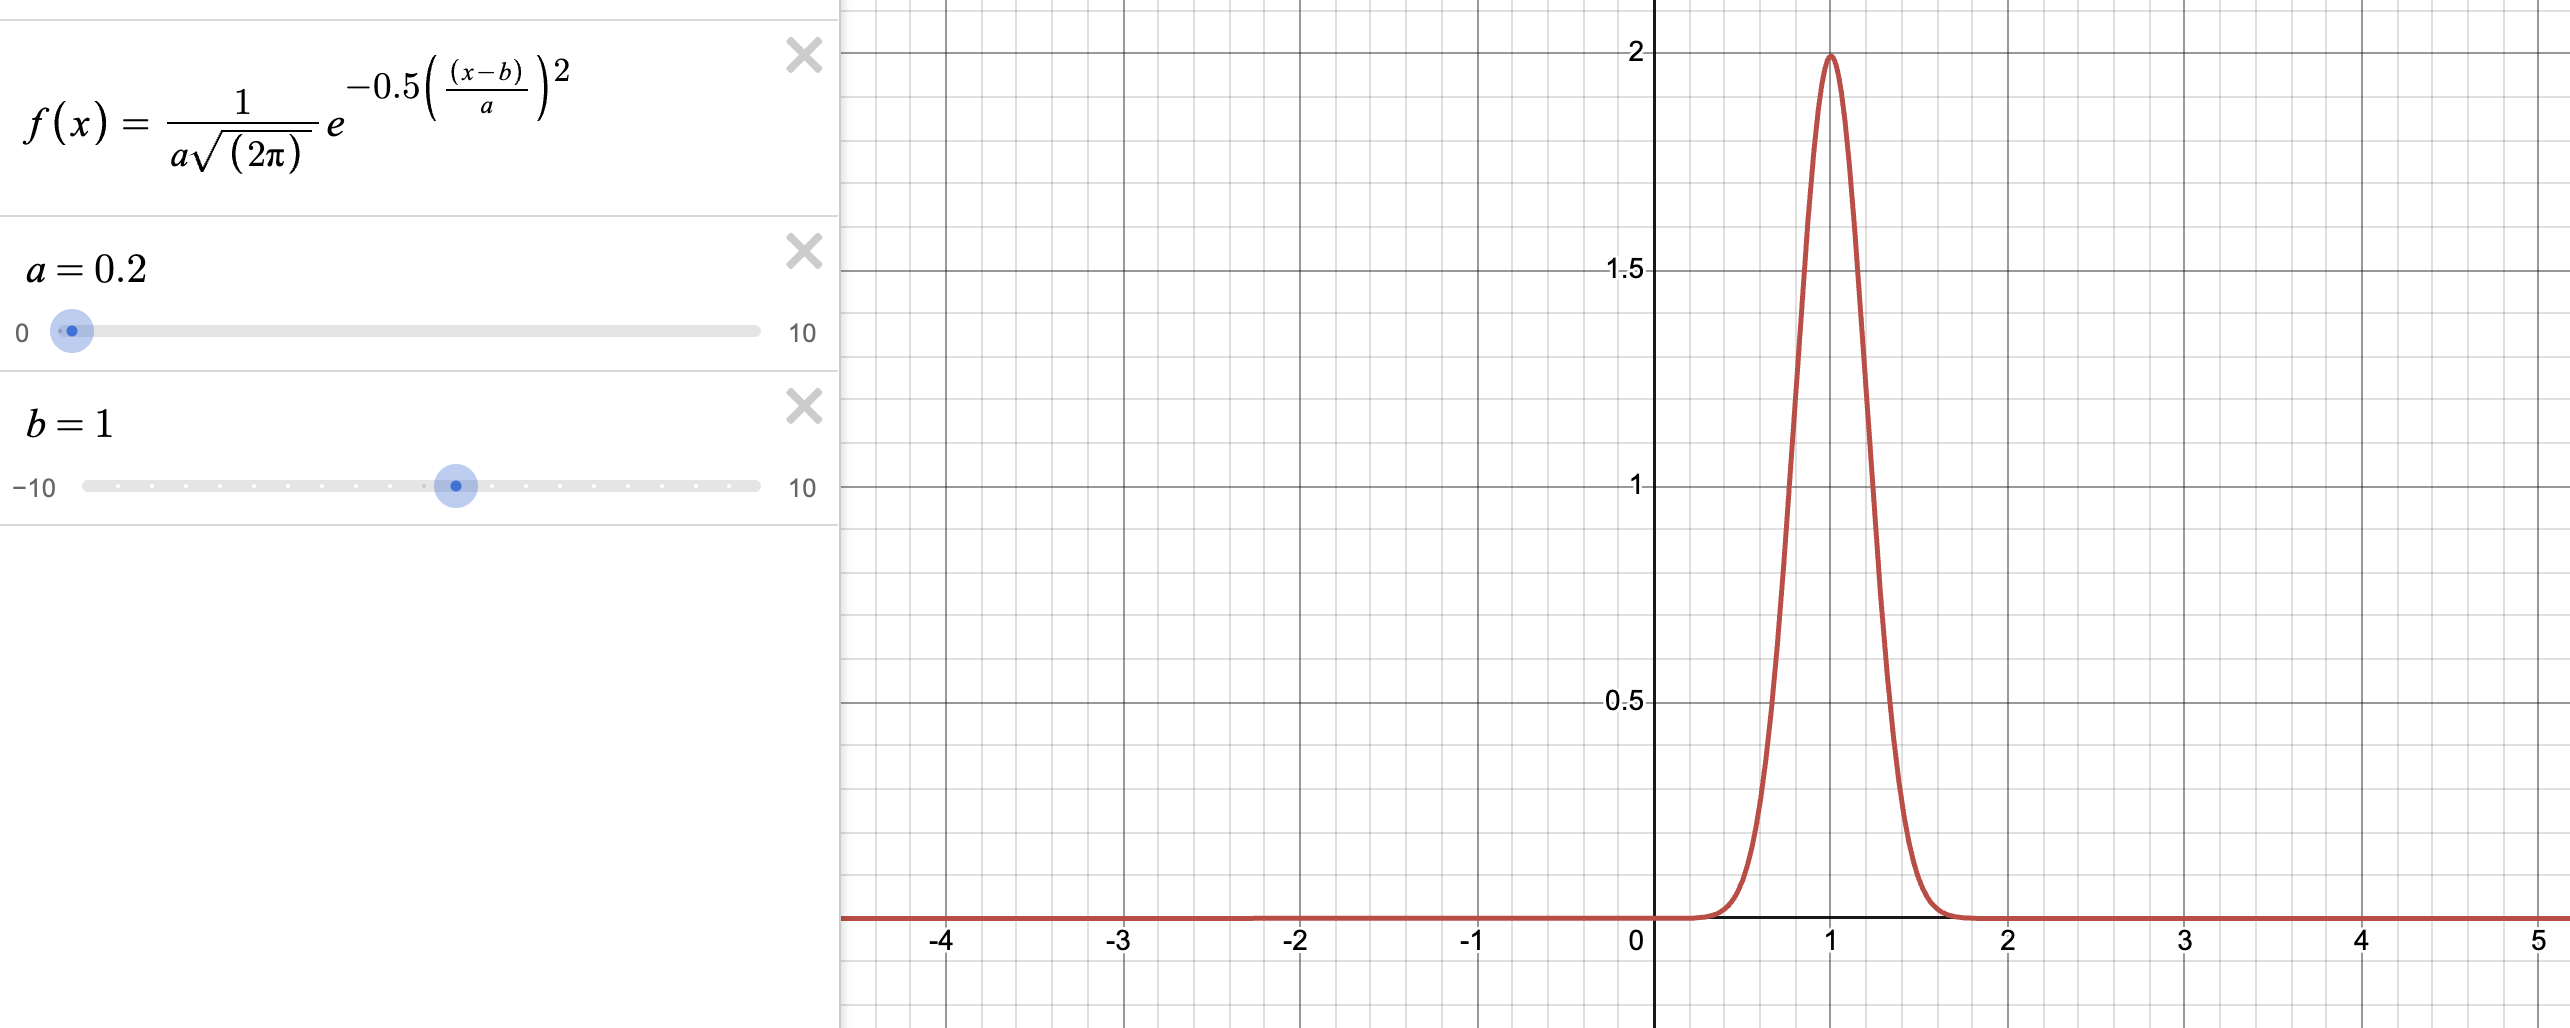

In [14]:
import torch
import re

def create_V_matrix(predicates):
    # Extract all variable names
    variable_set = set()
    predicate_vars = []
    for pred in predicates:
        # Extract variables inside parentheses
        vars_in_pred = re.findall(r'\((.*?)\)', pred)
        if vars_in_pred:
            vars_list = [v.strip() for v in vars_in_pred[0].split(',')]
        else:
            vars_list = []
        predicate_vars.append(vars_list)
        variable_set.update(vars_list)
    # Sort variables for consistent column order
    variables = sorted(variable_set, key=lambda x: (int(x[1:]) if x[1:].isdigit() else x))
    var_idx = {v: i for i, v in enumerate(variables)}
    # Build the matrix
    V = torch.zeros((len(predicates), len(variables)), dtype=torch.float32)
    for i, vars_list in enumerate(predicate_vars):
        for v in vars_list:
            V[i, var_idx[v]] = 1.0
    return V, variables

## Network

In [42]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import math
import numpy as np

# Define CustomNeuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])
        self.raw_sigmoid_center_weight = nn.Parameter(torch.randn(num_rules) * 0.1)  # Small init to prevent saturation
        # self.final_output_raw_sigmoid_center_weight = nn.Parameter(torch.randn(1) * 0.1)

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []
        self.adjust_sigmoid_center = 0.5 * torch.sigmoid(self.raw_sigmoid_center_weight)  # Ensure sigmoid center is between 0 and 0.5
        # self.final_output_sigmoid_center_weight = 0.5 * torch.sigmoid(self.final_output_raw_sigmoid_center_weight)  # Ensure sigmoid center is between 0 and 0.5
        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            rule_output = torch.exp(sum(conjunctions))
            activated_rule_output = torch.sigmoid(5 * (rule_output - self.adjust_sigmoid_center[i]))
            rule_outputs.append(activated_rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        # fuzzy_or = torch.sigmoid(fuzzy_or - self.final_output_sigmoid_center_weight)
        return fuzzy_or


V_matrix:
 tensor([[1., 1., 0.],
        [1., 0., 0.],
        [0., 1., 1.],
        [1., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/5 Final Loss: 0.4308
Restart 2/5 Final Loss: 0.4308
Restart 3/5 Final Loss: 0.4313
Restart 4/5 Final Loss: 0.4309
Restart 5/5 Final Loss: 0.4310


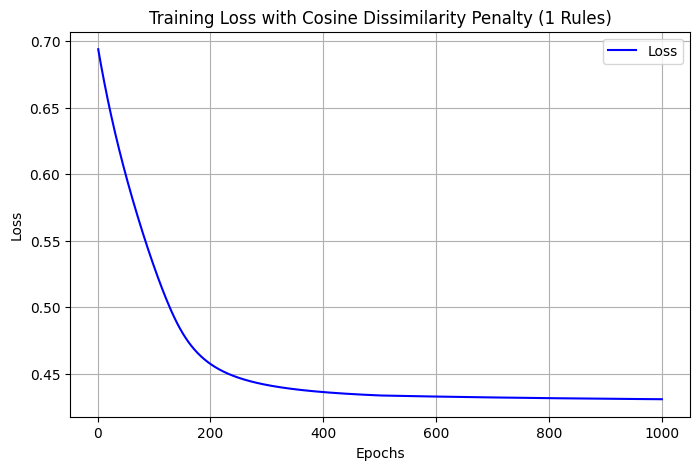

The most repeated rule is: 'h1 :- not(b1(X1, X2)) and not(b2(X1)) and b3(X2, X3).'
It appears 498 times out of 500.

Final Rule:
h :- not(b1(X1, X2)) and not(b2(X1)) and b3(X2, X3).

Final M matrices:
M1: [1.9932312965393066, 1.9885766506195068, 1.0013320446014404]


In [41]:
# Re-execution after kernel reset
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter

# Parameters
num_rules = 1
num_neurons_per_rule = 4
input_dim = 4
num_samples = 500
num_epochs = 1000
num_restarts = 5
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
X_train[:, 1] = X_train[:, 0]
y_train = ((1 - X_train[:, 0]) * X_train[:, 2] > 0.25).float()

# Body predicates and their variables
# B = {b1(X1, X2), b2(X1), b3(X2, X3), b4(X1, X3)}
predicates = ["b1(X1, X2)", "b2(X1)", "b3(X2, X3)", "b4(X1, X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        head_vars = [0, 2]
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        # range_restricted_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
        # range_restricted_loss is computed using this function: F(x) = sigmoid(-10 * (x - 0.5))
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        # The only auxiliary variable is X2
        connected_vars = [1]
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        import math
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term + 0.1 * range_restricted_loss + 0.1 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {M}")

## Even Dataset

In [23]:
import numpy as np

# Define the number range
numbers = list(range(21))  # 0 to 100
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

def encode_predicates(x1, x2, x3):
    # Each predicate returns True/False
    predicates = [
        int(x1 == 0),                 # zero(X1)
        int(x2 == 0),                 # zero(X2)
        int(x3 == 0),                 # zero(X3)
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))              # target(X2)
    ]
    # predicates = [
    #     int(x2 == x1 + 1),            # successor(X1, X2)
    #     int(x3 == x2 + 1),            # successor(X2, X3)
    #     int(x3 == x1 + 1),            # successor(X1, X3)
    #     int(is_even(x1))             # target(X1)
    # ]
    return predicates

# Construct the dataset
for x1 in numbers:
    for x2 in numbers:
        for x3 in numbers:
            x_feats = encode_predicates(x1, x2, x3)
            label = int(is_even(x3))  # target(X3) as label
            X_train.append(x_feats)
            y_train.append(label)

# Convert to numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

# # Replace all 1 elements in X_train with 0.9
# X_train[X_train == 1] = 0.9
# Replace all 0 elements in X_train with 0.1
X_train[X_train == 0] = 0.01
print("X_train shape:", X_train.shape)  # Should be (101*101*101, 8)
print("y_train shape:", y_train.shape)


X_train shape: (9261, 8)
y_train shape: (9261,)


In [40]:
import numpy as np

# Limit the number range for faster experimentation
max_n = 20
numbers = list(range(max_n + 1))  # 0 to max_n
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

# def encode_predicates(x1, x2, x3):
#     predicates = [
#         int(x1 == 0),                 # zero(X1)
#         int(x2 == 0),                 # zero(X2)
#         int(x3 == 0),                 # zero(X3)
#         int(x2 == x1 + 1),            # successor(X1, X2)
#         int(x3 == x2 + 1),            # successor(X2, X3)
#         int(x3 == x1 + 1),            # successor(X1, X3)
#         int(is_even(x1)),             # target(X1)
#         int(is_even(x2))              # target(X2)
#     ]
#     return predicates
def encode_predicates(x1, x2, x3):
    predicates = [
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))             # target(X2)
    ]
    return predicates
# Focused rule chains: X1=i, X2=i+1, X3=i+2 to align with recursive rule structure
for i in range(max_n - 1):  # Ensure i+2 <= max_n
    x1 = i
    x2 = i + 1
    x3 = i + 2
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))  # target(X3) as label
    X_train.append(x_feats)
    y_train.append(label)

# Add a few noise samples with random triples
np.random.seed(42)
for _ in range(10):
    x1, x2, x3 = np.random.choice(numbers, 3, replace=True)
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))
    X_train.append(x_feats)
    y_train.append(label)

# Convert to numpy arrays
X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

# # Replace all 1 elements in X_train with 0.9
# X_train[X_train == 1] = 0.9
# Replace all 0 elements in X_train with 0.1
X_train[X_train == 0] = 0.01
print("X_train shape:", X_train.shape)  # Should be (101*101*101, 8)
print("y_train shape:", y_train.shape)

X_train shape: (29, 5)
y_train shape: (29,)


Restart 1/1 Final Loss: 1.0913
Restart 1/1 Final Loss: 1.0547
Restart 1/1 Final Loss: 1.0966


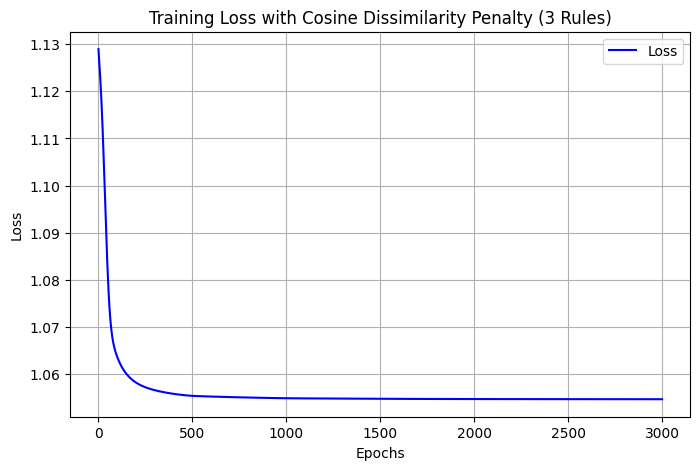


Final M matrices:
M1: [2. 2. 2.]
M2: [3. 3. 2.]
The most repeated rule is: 'h1 :- successor(X1, X3) and not(target(X2)).'
It appears 1642 times out of 4000.
The most repeated rule is: 'h2 :- not(zero(X1)) and zero(X2) and zero(X3) and successor(X1, X2) and successor(X2, X3) and target(X1).'
It appears 580 times out of 4000.

Final Rule:
target(X3) :- successor(X1, X3) and not(target(X2)) OR not(zero(X1)) and zero(X2) and zero(X3) and successor(X1, X2) and successor(X2, X3) and target(X1).


In [44]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import math

# Parameters
Num_rules = 3
num_neurons_per_rule = X_train.shape[1]  # Number of features in X_train
input_dim = num_neurons_per_rule
# num_samples = X_train.shape[0]  # Number of samples in X_train
num_samples = 4000  # For testing, we can use a smaller number of samples
num_epochs = 3000
num_restarts = 1

# Loss weights
sim_weight = 0.1
ent_weight = 0.01
rr_weight = 0.1
conn_weight = 0.1

# Random Dataset
# torch.manual_seed(42)
input_dim = 8  # Number of features in X_train
num_neurons_per_rule = input_dim  # Number of neurons per rule
X_train = torch.rand(num_samples, input_dim)
# y_train = ((((X_train[:, 6] > 0.5) & (X_train[:, 3] > 0.5)) & (X_train[:, 4] > 0.5)) | (X_train[:, 2] > 0.5)).float()
y_train = (((X_train[:, 6] * X_train[:, 3] * X_train[:, 4] > 0.125)) | (X_train[:, 2] > 0.5)).float()

# X_train = torch.tensor(X_train, dtype=torch.float32)
# y_train = torch.tensor(y_train, dtype=torch.float32)
# put the second column same as the first column

# Target body predicates and their variables
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

# Variables
variables = ["X1", "X2", "X3"]  # Assuming we have 3 variables

# Define predicate-variable binary matrix 
# Here the variables are known for each predicate
# update variable_matrix to match the predicates ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

variable_matrix = torch.tensor([
    [1, 0, 0],  # zero(X1)
    [0, 1, 0],  # zero(X2)
    [0, 0, 1],  # zero(X3)
    [1, 1, 0],  # successor(X1, X2)
    [0, 1, 1],  # successor(X2, X3)
    [1, 0, 1],  # successor(X1, X3)
    [1, 0, 0],  # target(X1)
    [0, 1, 0],  # target(X2)
], dtype=torch.float32)

# Head variables for the rule
head_variables = ["X3"]  # Assuming the head variables are X3
# Define head variables indices
# Assuming the head variables are X1 and X3, we can define their indices
head_vars = [2]  # Assuming the head variables are X3
connected_vars = [0, 1]  # Auxiliary variables X1 and X2

# print("V_matrix:\n", V_matrix)
# print("Variable order:", variable_order)

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for num_rule in range(Num_rules):
    num_rules = num_rule + 1  # Increment the number of rules for each restart
    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, variable_matrix)
        criterion = nn.BCEWithLogitsLoss()
        # criterion = nn.BCELoss()
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
        
        losses_nsre = []
        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Compute range resticted loss -> the probability of the head variables being present in the rule
            M = model_nsre.M_matrices
            # Find the corresponding values of M to head variables (here Variable 1 and 3)
            M_head = [M[i][head_vars] for i in range(num_rules)]
            # Multiply the elements of M_head
            head_var_probs = torch.prod(torch.stack(M_head), dim=0)
            # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
            range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
            # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

            # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
            # The only auxiliary variable is X2
            M_connected = [M[i][connected_vars] for i in range(num_rules)]

            # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
            Sum_Fx = 0.0
            for i, M in enumerate(M_connected):
                mean = 1.0
                std = 0.2
                Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
            connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

            entropy_term = sum(model_nsre.entropies)

            total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term + rr_weight * range_restricted_loss + conn_weight * connected_loss
            total_loss.sum().backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.sum().item())

            # print V matrix
            # print("V matrix:", model_nsre.V.detach().numpy())

        final_loss = losses_nsre[-1]
        print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
        if final_loss < best_loss:
            best_loss = final_loss
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre

# Load best model and compute M
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
filtered_state_dict = {k: v for k, v in best_state_dict.items() if k in model_keys}
best_model.load_state_dict(filtered_state_dict, strict=False)

_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")

Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


In [18]:
import numpy as np

# Limit the number range for faster experimentation
max_n = 30
numbers = list(range(max_n + 1))  # 0 to max_n
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

# def encode_predicates(x1, x2, x3):
#     predicates = [
#         int(x1 == 0),                 # zero(X1)
#         int(x2 == 0),                 # zero(X2)
#         int(x3 == 0),                 # zero(X3)
#         int(x2 == x1 + 1),            # successor(X1, X2)
#         int(x3 == x2 + 1),            # successor(X2, X3)
#         int(x3 == x1 + 1),            # successor(X1, X3)
#         int(is_even(x1)),             # target(X1)
#         int(is_even(x2))              # target(X2)
#     ]
#     return predicates
def encode_predicates(x1, x2, x3):
    predicates = [
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))             # target(X2)
    ]
    return predicates
# Focused rule chains: X1=i, X2=i+1, X3=i+2 to align with recursive rule structure
for i in range(max_n - 1):  # Ensure i+2 <= max_n
    x1 = i
    x2 = i + 1
    x3 = i + 2
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))  # target(X3) as label
    X_train.append(x_feats)
    y_train.append(label)

# Add a few noise samples with random triples
np.random.seed(42)
for _ in range(10):
    x1, x2, x3 = np.random.choice(numbers, 3, replace=True)
    x_feats = encode_predicates(x1, x2, x3)
    label = int(is_even(x3))
    X_train.append(x_feats)
    y_train.append(label)

# Convert to numpy arrays
X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

# # Replace all 1 elements in X_train with 0.9
# X_train[X_train == 1] = 0.9
# Replace all 0 elements in X_train with 0.1
X_train[X_train == 0] = 0.1 * np.random.rand(*X_train[X_train == 0].shape)  # Small random value instead of 0.1
print("X_train shape:", X_train.shape)  # Should be (101*101*101, 8)
print("y_train shape:", y_train.shape)

X_train shape: (39, 5)
y_train shape: (39,)


In [9]:
import numpy as np

# Define the number range (adjust max_n for larger datasets)
max_n = 15
numbers = list(range(max_n + 1))
X_train = []
y_train = []

def is_even(x):
    return x % 2 == 0

def encode_predicates(x1, x2, x3):
    return [
        int(x1 == 0),                 # zero(X1)
        int(x2 == 0),                 # zero(X2)
        int(x3 == 0),                 # zero(X3)
        int(x2 == x1 + 1),            # successor(X1, X2)
        int(x3 == x2 + 1),            # successor(X2, X3)
        int(x3 == x1 + 1),            # successor(X1, X3)
        int(is_even(x1)),             # target(X1)
        int(is_even(x2))              # target(X2)
    ]

for x1 in numbers:
    for x2 in numbers:
        for x3 in numbers:
            feats = encode_predicates(x1, x2, x3)
            # Rule 1: target(X3) :- zero(X3)
            rule1 = feats[2] == 1
            # Rule 2: target(X3) :- target(X1), successor(X1, X2), successor(X2, X3)
            rule2 = feats[6] == 1 and feats[3] == 1 and feats[4] == 1
            label = int(rule1 or rule2)
            X_train.append(feats)
            y_train.append(label)

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

# Optionally, replace 0s with a small value for fuzzy logic
X_train[X_train == 0] = 0.001

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (4096, 8)
y_train shape: (4096,)


In [26]:
import torch

# Settings
num_samples = 10000
input_dim = 8  # Number of predicates

# Random binary features (values in {0, 1})
torch.manual_seed(42)
X_train = (torch.rand(num_samples, input_dim)).float()
# X_train[X_train == 0] = 0.01  # Replace 0s with a small value for fuzzy logic

# Predicate indices for readability
ix_zero_X3 = 2
ix_succ_X1_X2 = 3
ix_succ_X2_X3 = 4
ix_target_X1 = 6

# Logical rule for y_train
y_train = (
    (   (X_train[:, 6] > 0.5) &
        (X_train[:, 3] > 0.5) &
        (X_train[:, 4] > 0.5) 
    )
).float()

# Optionally, replace 0s with a small value for fuzzy logic
# X_train[X_train == 0] = 0.001

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: torch.Size([10000, 8])
y_train shape: torch.Size([10000])


*** Another problem found: When the inputs are zero, the weights are not updated, because we don't have bias in the network weights! ***

One solution is to perturb data when they are zero. We can use random data close to zero!

In [25]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import math

# Parameters
Num_rules = 5
num_neurons_per_rule = X_train.shape[1]  # Number of features in X_train
input_dim = num_neurons_per_rule
num_samples = X_train.shape[0]  # Number of samples in X_train
num_epochs = 3000
num_restarts = 1

# Loss weights
sim_weight = 0.5
ent_weight = 0.01
rr_weight = 0.1
conn_weight = 0.1
fidelity_weight = 1.0


# Target body predicates and their variables
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

# Variables
variables = ["X1", "X2", "X3"]  # Assuming we have 3 variables

# Define predicate-variable binary matrix 
# Here the variables are known for each predicate
# update variable_matrix to match the predicates ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]

variable_matrix = torch.tensor([
    [1, 0, 0],  # zero(X1)
    [0, 1, 0],  # zero(X2)
    [0, 0, 1],  # zero(X3)
    [1, 1, 0],  # successor(X1, X2)
    [0, 1, 1],  # successor(X2, X3)
    [1, 0, 1],  # successor(X1, X3)
    [1, 0, 0],  # target(X1)
    [0, 0, 1],  # target(X2)
], dtype=torch.float32)

# Head variables for the rule
head_variables = ["X3"]  # Assuming the head variables are X3
# Define head variables indices
# Assuming the head variables are X1 and X3, we can define their indices
head_vars = [2]  # Assuming the head variables are X3
connected_vars = [0, 1]  # Auxiliary variables X1 and X2

# print("V_matrix:\n", V_matrix)
# print("Variable order:", variable_order)

# Convert to tensors
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)
# train_loader = DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=64, shuffle=True)

# Define cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

Num_rules = [1, 2, 3]  # List of rule counts to test

for num_rule in Num_rules:
    num_rules = num_rule
    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, variable_matrix)
        criterion = nn.BCELoss()
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []
        for epoch in range(num_epochs):
            epoch_loss = 0.0
            # for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model_nsre(X_tensor).squeeze()
            bce_loss = criterion(outputs, y_tensor)

            # Cosine similarity penalty
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    penalty += cosine(wi, wj).mean()

            # Range-restricted loss
            M = model_nsre.M_matrices
            M_head = [M[i][head_vars] for i in range(num_rules)]
            head_var_probs = torch.prod(torch.stack(M_head), dim=0)
            rr_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))

            # Connected loss
            M_connected = [M[i][connected_vars] for i in range(num_rules)]
            Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
            conn_loss = 0.5 * Sum_Fx / len(M_connected)

            # Entropy and Fidelity
            entropy_term = sum(model_nsre.entropies)
            # fidelity_loss = compute_batch_fidelity_loss(model_nsre, X_tensor, y_tensor, predicates)

            # Total loss
            total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term \
                            + rr_weight * rr_loss + conn_weight * conn_loss #+ fidelity_weight * fidelity_loss

            total_loss.sum().backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += total_loss.sum().item()

            scheduler.step()
            losses_nsre.append(epoch_loss)

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            best_num_rules = num_rules

# Load best model and compute M
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
filtered_state_dict = {k: v for k, v in best_state_dict.items() if k in model_keys}
best_model.load_state_dict(best_state_dict)

_ = best_model(X_tensor)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")

Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_10158/397815503.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_tensor = torch.tensor(X_train, dtype=torch.float32)
/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_10158/397815503.py:61: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_tensor = torch.tensor(y_train, dtype=torch.float32)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x4 and 8x3)

In [85]:
# create a dataframe for the dataset (X_train and y_train)
import pandas as pd
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]
data = pd.DataFrame(X_train.numpy(), columns=[f"{pred}" for pred in predicates])
data['y=target(X3)'] = y_train.numpy()
data.head(20)

,zero(X1),zero(X2),zero(X3),"successor(X1, X2)","successor(X2, X3)","successor(X1, X3)",target(X1),target(X2),y=target(X3)
0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0
1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0
3,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0
5,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
6,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0
7,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
8,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0
9,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


## Add Curriculum Learning

/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_1231/2521931859.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_tensor = torch.tensor(X_train, dtype=torch.float32)
/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_1231/2521931859.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_tensor = torch.tensor(y_train, dtype=torch.float32)



Learning Rule #1
Num Rules: 2, Restart 1/3, Final Loss: 0.3976.
Restart 1: acc_ratio = 0.6455
Num Rules: 2, Restart 2/3, Final Loss: 0.3988.
Restart 2: acc_ratio = 0.6476
Num Rules: 2, Restart 3/3, Final Loss: 0.3971.
Restart 3: acc_ratio = 0.6439
Best acc_ratio for Rule 1: 0.6476
Stopping curriculum learning as acc_ratio threshold met.


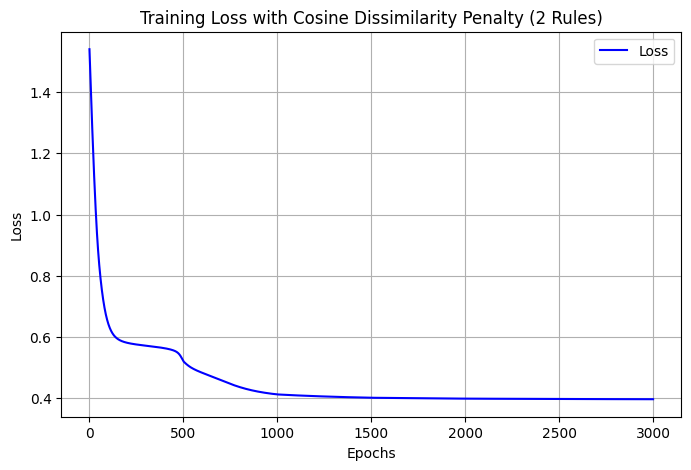


Final M matrices:
M1: [2. 2. 1.]


IndexError: list index out of range

In [ ]:

# Setup
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)
input_dim = X_tensor.shape[1]
num_neurons_per_rule = input_dim
variable_matrix = torch.tensor([
    [1, 0, 0], [0, 1, 0], [0, 0, 1],
    [1, 1, 0], [0, 1, 1], [1, 0, 1],
    [1, 0, 0], [0, 0, 1]
], dtype=torch.float32)
head_vars = [2]
connected_vars = [0, 1]
num_epochs = 3000
num_restarts = 3
max_rules = 5
acc_threshold = 0.6
sim_weight, ent_weight, rr_weight, conn_weight = 0.5, 0.01, 0.1, 0.1

frozen_state_dicts = []
best_rules_models = []

best_loss = float('inf')
best_losses = []

# Curriculum Learning Loop
for rule_idx in range(max_rules):
    print(f"\nLearning Rule #{rule_idx+1}")
    best_acc_ratio = -1.0
    best_state_dict = None
    best_model = None
    best_loss = np.inf

    for restart in range(num_restarts):
        model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)

        if rule_idx > 0:
            with torch.no_grad():
                for i, rule in enumerate(model.rules[:-1]):
                    for j, neuron in enumerate(rule):
                        neuron.raw_weights.copy_(frozen_state_dicts[i][j])
                        neuron.raw_weights.requires_grad = False

        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=0.01)
        criterion = nn.BCELoss()
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
        losses = []
        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model(X_tensor).squeeze()
            bce_loss = criterion(outputs, y_tensor)

            penalty = 0.0
            for i in range(rule_idx + 1):
                for j in range(i + 1, rule_idx + 1):
                    wi = model.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model.saved_weights[j].view(num_neurons_per_rule, -1)
                    penalty += nn.CosineSimilarity(dim=1)(wi, wj).mean()

            M = model.M_matrices
            M_head = [M[i][head_vars] for i in range(rule_idx + 1)]
            head_var_probs = torch.prod(torch.stack(M_head), dim=0)
            rr_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))

            M_connected = [M[i][connected_vars] for i in range(rule_idx + 1)]
            Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
            conn_loss = 0.5 * Sum_Fx / len(M_connected)

            entropy_term = sum(model.entropies)
            total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term \
                         + rr_weight * rr_loss + conn_weight * conn_loss

            total_loss.sum().backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses.append(total_loss.sum().item())

        final_loss = losses[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict_loss = deepcopy(model.state_dict())
            best_losses = losses

        acc = compute_acc_ratio(model, X_tensor, y_tensor, rule_idx)
        print(f"Restart {restart+1}: acc_ratio = {acc:.4f}")
        if acc > best_acc_ratio:
            best_acc_ratio = acc
            best_state_dict = [neuron.raw_weights.detach().clone() for neuron in model.rules[rule_idx]]
            # Save the model's state_dict instead of deepcopy
            best_model_state = model.state_dict()
            best_num_rules = rule_idx + 1

        # for i in range(rule_idx + 1):
        #     rule_acc_ratio = compute_acc_ratio(model, X_tensor, y_tensor, i)
        #     print(f"Rule {rule_idx+1} Restart {restart+1}: acc_ratio = {rule_acc_ratio:.4f}")
    frozen_state_dicts.append(best_state_dict)
    # Recreate the model and load the best state_dict
    best_model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)
    best_model.load_state_dict(best_model_state)
    best_rules_models.append(best_model)
    print(f"Best acc_ratio for Rule {rule_idx+1}: {best_acc_ratio:.4f}")
    if best_acc_ratio >= acc_threshold:
        print("Stopping curriculum learning as acc_ratio threshold met.")
        break
# Load best model and compute M
# Use best_num_rules to match the state_dict
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
best_model.load_state_dict(best_model_state)

_ = best_model(X_tensor)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")


Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")

/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_1541/1890353208.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_tensor = torch.tensor(X_train, dtype=torch.float32)
/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_1541/1890353208.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_tensor = torch.tensor(y_train, dtype=torch.float32)


Trained Rule 1/3, Final Loss: 0.2203
Trained Rule 2/3, Final Loss: 0.3714
Trained Rule 3/3, Final Loss: 0.8950


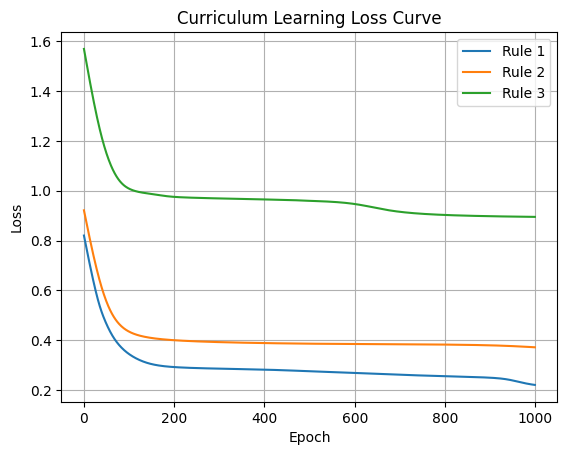

The most repeated rule is: 'h1 :- successor(X1, X2) and successor(X2, X3) and target(X1).'
It appears 7806 times out of 10000.
The most repeated rule is: 'h2 :- zero(X1) and not(zero(X2)) and not(target(X1)) and ?.'
It appears 996 times out of 10000.
The most repeated rule is: 'h3 :- zero(X1) and zero(X2) and zero(X3).'
It appears 8130 times out of 10000.

Final Rule:
target(X3) :- successor(X1, X2) and successor(X2, X3) and target(X1) OR zero(X1) and not(zero(X2)) and not(target(X1)) and ? OR zero(X1) and zero(X2) and zero(X3).


In [44]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import math
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Define Dataset
# ---------------------------

X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)

# ---------------------------
# Define NSDRE Model
# ---------------------------
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super().__init__()
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions, rule_weights, entropy_sum, P = [], [], 0.0, []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % x.shape[1]]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])
            self.saved_weights.append(torch.cat(rule_weights))
            self.entropies.append(entropy_sum)
            M = torch.matmul(torch.stack(P), self.V)
            self.M_matrices.append(M)
            rule_outputs.append(torch.exp(sum(conjunctions)))

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r
        return fuzzy_or

# ---------------------------
# Curriculum Learning Training
# ---------------------------
def freeze_rule_weights(rule_module):
    for neuron in rule_module:
        neuron.raw_weights.requires_grad = False

def train_with_curriculum_learning(X_tensor, y_tensor, total_num_rules, variable_matrix, num_neurons_per_rule, input_dim, num_epochs=1000, lr=0.01):
    cosine = nn.CosineSimilarity(dim=1)
    criterion = nn.BCELoss()
    sim_weight, ent_weight, rr_weight, conn_weight = 0.5, 0.01, 0.1, 0.1
    head_vars = [2]
    connected_vars = [1]

    frozen_rules, all_weights, best_losses = [], [], []

    for rule_idx in range(total_num_rules):
        num_rules = rule_idx + 1
        model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, variable_matrix)
        for i, frozen_rule in enumerate(frozen_rules):
            for j, neuron in enumerate(frozen_rule):
                model.rules[i][j].raw_weights.data = neuron.raw_weights.data.clone()
                model.rules[i][j].raw_weights.requires_grad = False

        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
        losses = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model(X_tensor).squeeze()
            bce_loss = criterion(outputs, y_tensor)

            penalty = sum(cosine(model.saved_weights[i].view(num_neurons_per_rule, -1),
                                 model.saved_weights[j].view(num_neurons_per_rule, -1)).mean()
                          for i in range(num_rules) for j in range(i + 1, num_rules))
            M = model.M_matrices
            M_head = [M[i][head_vars] for i in range(num_rules)]
            rr_loss = nn.MSELoss()(torch.prod(torch.stack(M_head), dim=0), torch.ones_like(y_tensor))
            M_connected = [M[i][connected_vars] for i in range(num_rules)]
            Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
            conn_loss = 0.5 * Sum_Fx / len(M_connected)
            entropy_term = sum(model.entropies)

            total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term + rr_weight * rr_loss + conn_weight * conn_loss
            total_loss.backward()
            # nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses.append(total_loss.item())

        print(f"Trained Rule {rule_idx+1}/{total_num_rules}, Final Loss: {losses[-1]:.4f}")
        best_losses.append(losses)

        # Instead of deepcopy, create new neurons and copy weights
        frozen_rule = []
        for neuron in model.rules[rule_idx]:
            new_neuron = CustomNeuron()
            new_neuron.raw_weights.data = neuron.raw_weights.data.clone()
            new_neuron.raw_weights.requires_grad = False
            frozen_rule.append(new_neuron)
        freeze_rule_weights(frozen_rule)
        frozen_rules.append(frozen_rule)

        rule_weights = [torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist() for neuron in model.rules[rule_idx]]
        all_weights.append(rule_weights)

    return all_weights, best_losses

# ---------------------------
# Variable matrix for predicates
# ---------------------------
variable_matrix = torch.tensor([
    [1, 0, 0],  # zero(X1)
    [0, 1, 0],  # zero(X2)
    [0, 0, 1],  # zero(X3)
    [1, 1, 0],  # successor(X1, X2)
    [0, 1, 1],  # successor(X2, X3)
    [1, 0, 1],  # successor(X1, X3)
    [1, 0, 0],  # target(X1)
    [0, 0, 1],  # target(X2)
], dtype=torch.float32)

# ---------------------------
# Run curriculum learning
# ---------------------------
all_weights, all_losses = train_with_curriculum_learning(
    X_tensor=X_tensor,
    y_tensor=y_tensor,
    total_num_rules=3,
    variable_matrix=variable_matrix,
    num_neurons_per_rule=X_tensor.shape[1],
    input_dim=X_tensor.shape[1],
    num_epochs=1000,
    lr=0.01
)

# ---------------------------
# Plot losses
# ---------------------------
for i, losses in enumerate(all_losses):
    plt.plot(losses, label=f"Rule {i+1}")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Curriculum Learning Loss Curve")
plt.legend()
plt.grid(True)
plt.show()

Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(all_weights):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


In [60]:
import torch

# Settings
num_samples = 10000
input_dim = 8  # Number of predicates

# Random binary features (values in {0, 1})
torch.manual_seed(42)
X_train = (torch.rand(num_samples, input_dim)).float()
# X_train[X_train == 0] = 0.01  # Replace 0s with a small value for fuzzy logic

# Predicate indices for readability
ix_zero_X3 = 2
ix_succ_X1_X2 = 3
ix_succ_X2_X3 = 4
ix_target_X1 = 6

# Logical rule for y_train
y_train = (
    (   (X_train[:, 6] > 0.5) &
        (X_train[:, 3] > 0.5) &
        (X_train[:, 4] > 0.5) |
        (X_train[:, 2] > 0.5)
    )
).float()

# Optionally, replace 0s with a small value for fuzzy logic
# X_train[X_train == 0] = 0.001

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: torch.Size([10000, 8])
y_train shape: torch.Size([10000])


In [71]:
# Re-run after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from copy import deepcopy
import math
import pandas as pd


# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)


class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions, rule_weights, entropy_sum, P = [], [], 0.0, []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % x.shape[1]]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])
            self.saved_weights.append(torch.cat(rule_weights))
            self.entropies.append(entropy_sum)
            M = torch.matmul(torch.stack(P), self.V)
            self.M_matrices.append(M)
            rule_outputs.append(torch.exp(sum(conjunctions)))

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r
        return fuzzy_or, rule_outputs


def evaluate_acc_ratio(body_outputs, y_true):
    with torch.no_grad():
        body_pred = (body_outputs > 0.5).float()
        head_pred = (y_true > 0.5).float()
        n_b = torch.sum(body_pred).item()
        n_hb = torch.sum(body_pred * (head_pred == 1)).item()
        if n_b == 0:
            return 0.0
        return n_hb / n_b


def train_rules_with_acc_ratio(X_tensor, y_tensor, variable_matrix, max_rules=3, restarts_per_rule=3, num_epochs=1000, acc_threshold=0.95):
    input_dim = X_tensor.shape[1]
    num_neurons_per_rule = input_dim
    criterion = nn.BCELoss()
    rr_weight, conn_weight, ent_weight = 0.1, 0.1, 0.01
    head_vars = [2]
    connected_vars = [1]

    frozen_rules = []
    rule_weights = []
    rule_acc_ratios = []

    for rule_idx in range(max_rules):
        best_acc = -1
        best_model_state = None

        for restart in range(restarts_per_rule):
            model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)

            for i, frozen_rule in enumerate(frozen_rules):
                for j, neuron_state in enumerate(frozen_rule):
                    model.rules[i][j].load_state_dict(neuron_state)
                    model.rules[i][j].raw_weights.requires_grad = False

            optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=0.01)

            for epoch in range(num_epochs):
                optimizer.zero_grad()
                outputs, rule_outputs = model(X_tensor)
                bce_loss = criterion(outputs.squeeze(), y_tensor)

                M = model.M_matrices
                M_head = [M[i][head_vars] for i in range(rule_idx + 1)]
                rr_loss = nn.MSELoss()(torch.prod(torch.stack(M_head), dim=0), torch.ones_like(y_tensor))

                M_connected = [M[i][connected_vars] for i in range(rule_idx + 1)]
                Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
                conn_loss = 0.5 * Sum_Fx / len(M_connected)

                entropy_term = sum(model.entropies)

                # Cosine similarity penalty
                penalty = 0.0
                for i in range(num_rules):
                    for j in range(i + 1, num_rules):
                        wi = model.saved_weights[i].view(num_neurons_per_rule, -1)
                        wj = model.saved_weights[j].view(num_neurons_per_rule, -1)
                        penalty += cosine(wi, wj).mean()

                total_loss = bce_loss + sim_weight * penalty + rr_weight * rr_loss + conn_weight * conn_loss - ent_weight * entropy_term
                total_loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            _, rule_outputs_final = model(X_tensor)
            acc_ratio = evaluate_acc_ratio(rule_outputs_final[-1], y_tensor)

            if acc_ratio > best_acc:
                best_acc = acc_ratio
                best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        rule_acc_ratios.append(best_acc)
        # Restore best model for this rule
        best_model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)
        best_model.load_state_dict(best_model_state)

        # Save each neuron's state_dict for freezing in the next rule
        best_rule = [deepcopy(neuron.state_dict()) for neuron in best_model.rules[-1]]
        for j, neuron_state in enumerate(best_rule):
            best_model.rules[-1][j].raw_weights.requires_grad = False
        frozen_rules.append(best_rule)

        weights = [torch.softmax(best_model.rules[-1][j].raw_weights, dim=0).detach().numpy().tolist() for j in range(num_neurons_per_rule)]
        rule_weights.append(weights)

        if all(r > acc_threshold for r in rule_acc_ratios):
            break

    return rule_weights, rule_acc_ratios


# Sample Data
torch.manual_seed(0)
num_samples = 100
input_dim = 8
# X_tensor = torch.randint(0, 2, (num_samples, input_dim)).float()
# y_tensor = ((X_tensor[:, 0] * X_tensor[:, 4]) > 0).float()
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)

variable_matrix = torch.tensor([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [1, 1, 0],
    [0, 1, 1],
    [1, 0, 1],
    [1, 0, 0],
    [0, 0, 1],
], dtype=torch.float32)

# Run training
rule_weights, rule_acc_ratios = train_rules_with_acc_ratio(
    X_tensor, y_tensor, variable_matrix,
    max_rules=3,
    restarts_per_rule=3,
    num_epochs=1000,
    acc_threshold=0.98
)

Predicate_values = X_tensor

Final_rules = []
all_Extracted_rules = []

if rule_weights and len(Predicate_values) > 0:
    for rule_num, weights in enumerate(rule_weights):
        Extracted_rules = []
        for i in range(len(Predicate_values)):
            pred_values = Predicate_values[i].numpy()
            try:
                preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
            except Exception as e:
                print(f"Error at rule_num={rule_num}, i={i}: {e}")
                preds = []
            if not isinstance(preds, list):
                preds = list(preds)
            refined_preds = [pred for pred in preds if pred != '1']
            rule_str = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
            Extracted_rules.append(rule_str)
        all_Extracted_rules.append(Extracted_rules)

        rule_counts = Counter(Extracted_rules)
        if len(rule_counts) > 0:
            most_common = rule_counts.most_common(1)
            if len(most_common) > 0:
                most_common_rule, count = most_common[0]
                print(f"The most repeated rule is: '{most_common_rule}'")
                print(f"It appears {count} times out of {len(Extracted_rules)}.")
                Final_rules.append(most_common_rule)
            else:
                print(f"No rules extracted for rule_num={rule_num}")
                Final_rules.append("")
        else:
            print(f"No rules extracted for rule_num={rule_num}")
            Final_rules.append("")
else:
    print("rule_weights is empty or Predicate_values is empty. Skipping rule extraction.")
    Final_rules = []

# Remove the "h{i+1} :- " part from each rule, only if it exists
Final_rules = [
    rule.replace(f"h{idx+1} :- ", "") if rule.startswith(f"h{idx+1} :- ") else rule
    for idx, rule in enumerate(Final_rules)
] if Final_rules else []

# Remove the "." at the end, only if it exists
Final_rules = [rule.rstrip(".") for rule in Final_rules] if Final_rules else []

# Convert the rules to a single rule
if Final_rules and any(Final_rules):
    final_rule = "target(X3) :- " + " OR ".join([r for r in Final_rules if r]) + "."
else:
    final_rule = "target(X3) :- ."

print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_1541/2871256810.py:164: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_tensor = torch.tensor(X_train, dtype=torch.float32)
/var/folders/y3/py52bzvn67nbjv67d4vr2ns80000gp/T/ipykernel_1541/2871256810.py:165: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_tensor = torch.tensor(y_train, dtype=torch.float32)


IndexError: list index out of range

## Find the rule for even/odd numbers

## Find the rule for grandparent/2 relationships

## Write a Function showing if some of the predicates are correlated

## How to add constraints to the network?

In [1]:
import torch

def softmin_attention(x, beta=10.0, mask=None):
    """
    x: Tensor of shape (batch_size, seq_len)
    beta: Controls sharpness of softmin. Higher = closer to hard min
    mask: Optional mask tensor of shape (batch_size, seq_len), 1 for valid, 0 for padding
    """
    scores = -beta * x  # negative scores to favor smaller x
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))
    
    weights = torch.softmax(scores, dim=-1)
    return (weights * x).sum(dim=-1), weights  # softmin value, attention weights


In [15]:
x = torch.tensor([[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
                  [0.3, 0.9, 0.1, 0.6, 0.2, 0.4, 0.8, 0.7],
                  [0.2, 0.5, 0.6, 0.1, 0.3, 0.4, 0.9, 0.8],
                  [0.7, 0.1, 0.4, 0.3, 0.5, 0.2, 0.6, 0.8],
                  [0.4, 0.7, 0.3, 0.1, 0.9, 0.5, 0.2, 0.6],
                  [0.8, 0.2, 0.5, 0.9, 0.1, 0.4, 0.7, 0.3]], requires_grad=True)

softmin_val, attn_weights = softmin_attention(x, beta=20)
print("Softmin:\n", softmin_val)
# show attention weights with formatting
print("Attention Weights:")
for i, weights in enumerate(attn_weights.detach().numpy()):
    weights = [f"{w:.4f}" for w in weights]
    print(f"Sample {i}: {weights}")


Softmin:
 tensor([0.5000, 0.1155, 0.1156, 0.1157, 0.1157, 0.1156],
       grad_fn=<SumBackward1>)
Attention Weights:
Sample 0: ['0.1250', '0.1250', '0.1250', '0.1250', '0.1250', '0.1250', '0.1250', '0.1250']
Sample 1: ['0.0158', '0.0000', '0.8649', '0.0000', '0.1171', '0.0021', '0.0000', '0.0000']
Sample 2: ['0.1170', '0.0003', '0.0000', '0.8647', '0.0158', '0.0021', '0.0000', '0.0000']
Sample 3: ['0.0000', '0.8647', '0.0021', '0.0158', '0.0003', '0.1170', '0.0000', '0.0000']
Sample 4: ['0.0021', '0.0000', '0.0158', '0.8647', '0.0000', '0.0003', '0.1170', '0.0000']
Sample 5: ['0.0000', '0.1170', '0.0003', '0.0000', '0.8647', '0.0021', '0.0000', '0.0158']
